# HealthyAir - Feature Engineering Notebook
Creates predictive features such as lag variables, rolling averages and time features.

## Feature engineering
1. Load and validate cleaned dataset
2. Create target
3. Check target distribution / class imbalance
4. Create lag features
5. Create rolling features
6. Create datetime features
7. Save feature dataset

Target defined first 
Class imbalance measured early 
Leakage-safe rolling features

The notebook creates model-ready features from the cleaned Air Quality dataset, time and lag features, measurements available at hour t to predict the NO2 measurement/category at hour t+1. 
A fixed seed makes resampling repeatable.

In [1]:
# Import Libraries
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import statsmodels
import scipy
import os
import gcsfs
import warnings
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    balanced_accuracy_score,
    f1_score
)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif
from statsmodels.stats.proportion import proportion_confint

SEED = 42
rng = np.random.default_rng(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 110)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 7)

def check(label, ok):
    """Self-check: prints PASS or CHECK AGAIN."""
    print(("PASS         " if bool(ok) else "CHECK AGAIN  ") + label)
    
# Confirm location and Libraries
# ----------------------------------------------------------------
print("Location:", sys.executable)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("statsmodels:", statsmodels.__version__)

Location: /home/chloekc/datahandling/healthyair/.venv/bin/python
Python: 3.12.3
NumPy: 2.5.3
pandas: 3.0.6
SciPy: 1.18.1
Matplotlib: 3.11.1
Seaborn: 0.13.2
statsmodels: 0.15.0


## 1. Load Clean Data & Validate

In [2]:
# Google Cloud Storage Configuration
# ---------------------------------------------------------------------
GCS_PROJECT_ID = "healthy_air_analysis"
GCS_BUCKET = "uci_air_quality_20119102"
GCS_FILE = "gs://uci_air_quality_20119102/data/processed/.csv"

# Data paths
# ---------------------------------------------------------------------
RAW_GCS_PATH = "data_raw/uci-air-quality_20119102/v1/AirQualityUCI.csv"
PROCESSED_GCS_PATH = "processed/v1/"

PROJECT_ROOT = Path.cwd().parent
while not (PROJECT_ROOT / ".git").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FEATURE_DIR = PROJECT_ROOT / "data" / "features"
FILE_PATH = PROCESSED_DIR/ "air_quality_cleaned.parquet"
df = pd.read_parquet(FILE_PATH)

# Data contract
# ----------------------------------------------------------------------
required = {"Date", "Time", "CO(GT)", "PT08.S1(CO)", "NMHC(GT)", "C6H6(GT)",
            "PT08.S2(NMHC)", "NOx(GT)", "PT08.S3(NOx)", "NO2(GT)", "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH"}
assert required.issubset(df.columns)
assert df["Datetime"].is_monotonic_increasing
print(df["Datetime"].is_monotonic_increasing)
print("Initial data-contract checks passed.")
print(f"Project: {GCS_PROJECT_ID}")
print(f"Bucket: gs://{GCS_BUCKET}")
print(f"Dataset:, {GCS_BUCKET}")
print(f"Rows: {df.shape[0]:,}; columns: {df.shape[1]}")
display(df.head())
# Remove NMHC(GT) due to 90% missingness
df_target = df.copy()

True
Initial data-contract checks passed.
Project: healthy_air_analysis
Bucket: gs://uci_air_quality_20119102
Dataset:, uci_air_quality_20119102
Rows: 9,357; columns: 16


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Datetime
0,3/10/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00
1,3/10/2004,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00
2,3/10/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00
3,3/10/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00
4,3/10/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00


## 2. Define categories/ Air Quality Thresholds

Class Distribution and Imbalance Analysis

In [3]:
# NO2 thresholds (µg/m³)
GOOD_THRESHOLD = 100
POOR_THRESHOLD = 200

# Three air-quality categories
categories = [
    df_target["NO2(GT)"] < GOOD_THRESHOLD,
    (df_target["NO2(GT)"] >= GOOD_THRESHOLD) &
    (df_target["NO2(GT)"] <= POOR_THRESHOLD),
    df_target["NO2(GT)"] > POOR_THRESHOLD
]

labels = ["GOOD", "MODERATE", "POOR"]

df_target["NO2_Category"] = np.select(
    categories,
    labels,
    default=None
)

# Check results
print(df_target[["NO2(GT)", "NO2_Category"]].head(10))

print("\nCategory counts:")
print(df_target["NO2_Category"].value_counts(dropna=False))

print("\nCategory percentages:")
print(
    df_target["NO2_Category"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)


   NO2(GT) NO2_Category
0    113.0     MODERATE
1     92.0         GOOD
2    114.0     MODERATE
3    122.0     MODERATE
4    116.0     MODERATE
5     96.0         GOOD
6     77.0         GOOD
7     76.0         GOOD
8     60.0         GOOD
9    109.0     MODERATE

Category counts:
NO2_Category
MODERATE    5713
GOOD        3258
POOR         386
Name: count, dtype: int64

Category percentages:
NO2_Category
MODERATE    61.06
GOOD        34.82
POOR         4.13
Name: proportion, dtype: float64


## 7. Class Imbalance Check

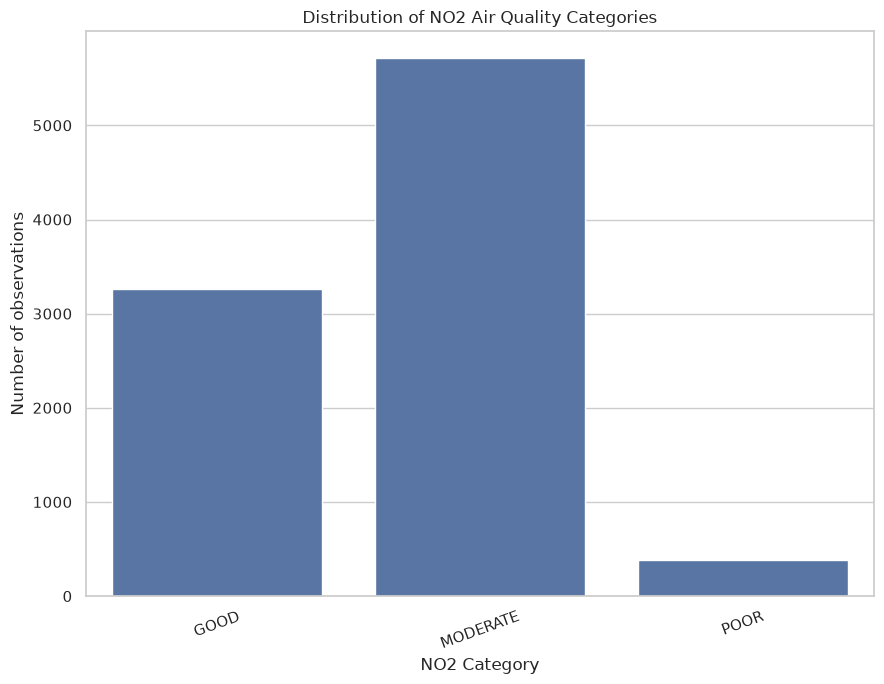

In [4]:
# Visualize
# -----------------------------------------------------------------------

sns.countplot(
    data=df_target,
    x="NO2_Category",
    order=["GOOD", "MODERATE", "POOR"]
)

plt.title("Distribution of NO2 Air Quality Categories")
plt.xlabel("NO2 Category")
plt.ylabel("Number of observations")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 2. Create next-hour target

In [5]:
df_target["Target_Next_Hour"] = (
    df_target["NO2_Category"]
    .shift(-1)
)
df_target["Target_Next_Hour"] \
    .value_counts(normalize=True) \
    .mul(100) \
    .round(2)

Target_Next_Hour
MODERATE    61.05
GOOD        34.82
POOR         4.13
Name: proportion, dtype: float64

<Axes: xlabel='Target_Next_Hour', ylabel='count'>

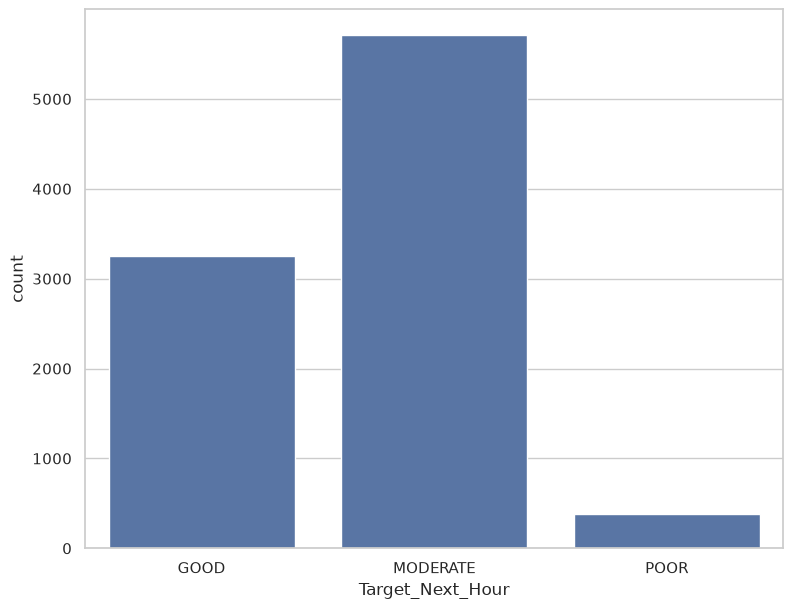

In [6]:
sns.countplot(
    data=df_target,
    x="Target_Next_Hour"
)

## 2. Lag and rolling features
These use past measurements only. The shift-before-rolling operation prevents the current row from entering its own rolling mean. Always validate time gaps in cleaning phase before relying on row-based lags.

In [7]:
# Select numerical measurement variables
measurement_cols = [
    "CO(GT)", "PT08.S1(CO)", "NMHC(GT)", "C6H6(GT)",
    "PT08.S2(NMHC)", "NOx(GT)", "PT08.S3(NOx)",
    "NO2(GT)", "PT08.S4(NO2)", "PT08.S5(O3)",
    "T", "RH", "AH"
]

In [8]:
lag_cols = [
    c
    for c in measurement_cols
    if c in df_target.columns
]
for col in lag_cols:
    df_target[f"{col}_lag_1"] = df_target[col].shift(1)
    df_target[f"{col}_lag_2"] = df_target[col].shift(2)
    df_target[f"{col}_rolling_mean_3"] = df_target[col].shift(1).rolling(3, min_periods=3).mean()
display(df_target[["Datetime"] + [f"{c}_lag_1" for c in lag_cols]].head())

,Datetime,CO(GT)_lag_1,PT08.S1(CO)_lag_1,NMHC(GT)_lag_1,C6H6(GT)_lag_1,PT08.S2(NMHC)_lag_1,NOx(GT)_lag_1,PT08.S3(NOx)_lag_1,NO2(GT)_lag_1,PT08.S4(NO2)_lag_1,PT08.S5(O3)_lag_1,T_lag_1,RH_lag_1,AH_lag_1
0,2004-03-10 18:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2004-03-10 19:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
2,2004-03-10 20:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
3,2004-03-10 21:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
4,2004-03-10 22:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867


In [9]:
display(
    df_target[
        ["Datetime"]
        +
        [
            f"{c}_lag_1"
            for c in lag_cols
        ]
    ].head()
)

,Datetime,CO(GT)_lag_1,PT08.S1(CO)_lag_1,NMHC(GT)_lag_1,C6H6(GT)_lag_1,PT08.S2(NMHC)_lag_1,NOx(GT)_lag_1,PT08.S3(NOx)_lag_1,NO2(GT)_lag_1,PT08.S4(NO2)_lag_1,PT08.S5(O3)_lag_1,T_lag_1,RH_lag_1,AH_lag_1
0,2004-03-10 18:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2004-03-10 19:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
2,2004-03-10 20:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
3,2004-03-10 21:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
4,2004-03-10 22:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867


In [10]:
display(
    df_target[
        [
            "Datetime",
            "NO2(GT)",
            "NO2(GT)_lag_1",
            "NO2(GT)_rolling_mean_3"
        ]
    ].head(10)
)


,Datetime,NO2(GT),NO2(GT)_lag_1,NO2(GT)_rolling_mean_3
0,2004-03-10 18:00:00,113.0,NaN,NaN
1,2004-03-10 19:00:00,92.0,113.0,NaN
2,2004-03-10 20:00:00,114.0,92.0,NaN
3,2004-03-10 21:00:00,122.0,114.0,106.333333
4,2004-03-10 22:00:00,116.0,122.0,109.333333
5,2004-03-10 23:00:00,96.0,116.0,117.333333
6,2004-03-11 00:00:00,77.0,96.0,111.333333
7,2004-03-11 01:00:00,76.0,77.0,96.333333
8,2004-03-11 02:00:00,60.0,76.0,83.000000
9,2004-03-11 03:00:00,109.0,60.0,71.000000


## 3. Datetime Features

In [11]:
df_target["hour"] = (
    df_target["Datetime"]
    .dt.hour
)

df_target["day_of_week"] = (
    df_target["Datetime"]
    .dt.dayofweek
)

df_target["month"] = (
    df_target["Datetime"]
    .dt.month
)

df_target["is_weekend"] = (
    df_target["day_of_week"] >= 5
).astype(int)
df_target.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,...,PT08.S5(O3)_lag_2,PT08.S5(O3)_rolling_mean_3,T_lag_1,T_lag_2,T_rolling_mean_3,RH_lag_1,RH_lag_2,RH_rolling_mean_3,AH_lag_1,AH_lag_2,AH_rolling_mean_3,hour,day_of_week,month,is_weekend
0,3/10/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18,2,3,0
1,3/10/2004,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,...,NaN,NaN,13.6,NaN,NaN,48.9,NaN,NaN,0.7578,NaN,NaN,19,2,3,0
2,3/10/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,...,1268.0,NaN,13.3,13.6,NaN,47.7,48.9,NaN,0.7255,0.7578,NaN,20,2,3,0
3,3/10/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,...,972.0,1104.666667,11.9,13.3,12.933333,54.0,47.7,50.2,0.7502,0.7255,0.744500,21,2,3,0
4,3/10/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,...,1074.0,1083.000000,11.0,11.9,12.066667,60.0,54.0,53.9,0.7867,0.7502,0.754133,22,2,3,0


## 7. Drop Nans

In [12]:
# Remove NA introduced by lags
df_target = (
    df_target
    .dropna()
    .reset_index(drop=True)
)

## 4. Save Features

In [13]:
feature_path = (
    PROJECT_ROOT /
    "data" /
    "features"
)

feature_path.mkdir(
    parents=True,
    exist_ok=True
)

df_target.to_parquet(
    feature_path /
    "air_quality_features.parquet",
    index=False
)

In [14]:
df_target.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,...,PT08.S5(O3)_lag_2,PT08.S5(O3)_rolling_mean_3,T_lag_1,T_lag_2,T_rolling_mean_3,RH_lag_1,RH_lag_2,RH_rolling_mean_3,AH_lag_1,AH_lag_2,AH_rolling_mean_3,hour,day_of_week,month,is_weekend
0,3/10/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,...,972.0,1104.666667,11.9,13.3,12.933333,54.0,47.7,50.200000,0.7502,0.7255,0.744500,21,2,3,0
1,3/10/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,...,1074.0,1083.000000,11.0,11.9,12.066667,60.0,54.0,53.900000,0.7867,0.7502,0.754133,22,2,3,0
2,3/10/2004,23:00:00,1.2,1197.0,38.0,4.7,750.0,89.0,1337.0,96.0,1393.0,949.0,11.2,59.2,0.7848,...,1203.0,1129.000000,11.2,11.0,11.366667,59.6,60.0,57.866667,0.7888,0.7867,0.775233,23,2,3,0
3,3/11/2004,0:00:00,1.2,1185.0,31.0,3.6,690.0,62.0,1462.0,77.0,1333.0,733.0,11.3,56.8,0.7603,...,1110.0,1087.333333,11.2,11.2,11.133333,59.2,59.6,59.600000,0.7848,0.7888,0.786767,0,3,3,0
4,3/11/2004,1:00:00,1.0,1136.0,31.0,3.3,672.0,62.0,1453.0,76.0,1333.0,730.0,10.7,60.0,0.7702,...,949.0,930.666667,11.3,11.2,11.233333,56.8,59.2,58.533333,0.7603,0.7848,0.777967,1,3,3,0


train_df = pd.read_parquet(
    PROJECT_ROOT /
    "data" /
    "processed" /
    "train.parquet"
)

eval_df = pd.read_parquet(
    PROJECT_ROOT /
    "data" /
    "processed" /
    "evaluation.parquet"
)

test_df = pd.read_parquet(
    PROJECT_ROOT /
    "data" /
    "processed" /
    "test.parquet"
)